In [1]:
import numpy as np
import pandas as pd

In [ ]:
'''
stage_1_rank1:
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'
##################
stage_2_rank1:
graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'
#################
stage_3_rank1:
graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


'''

## stage1

In [2]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values 

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name #.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


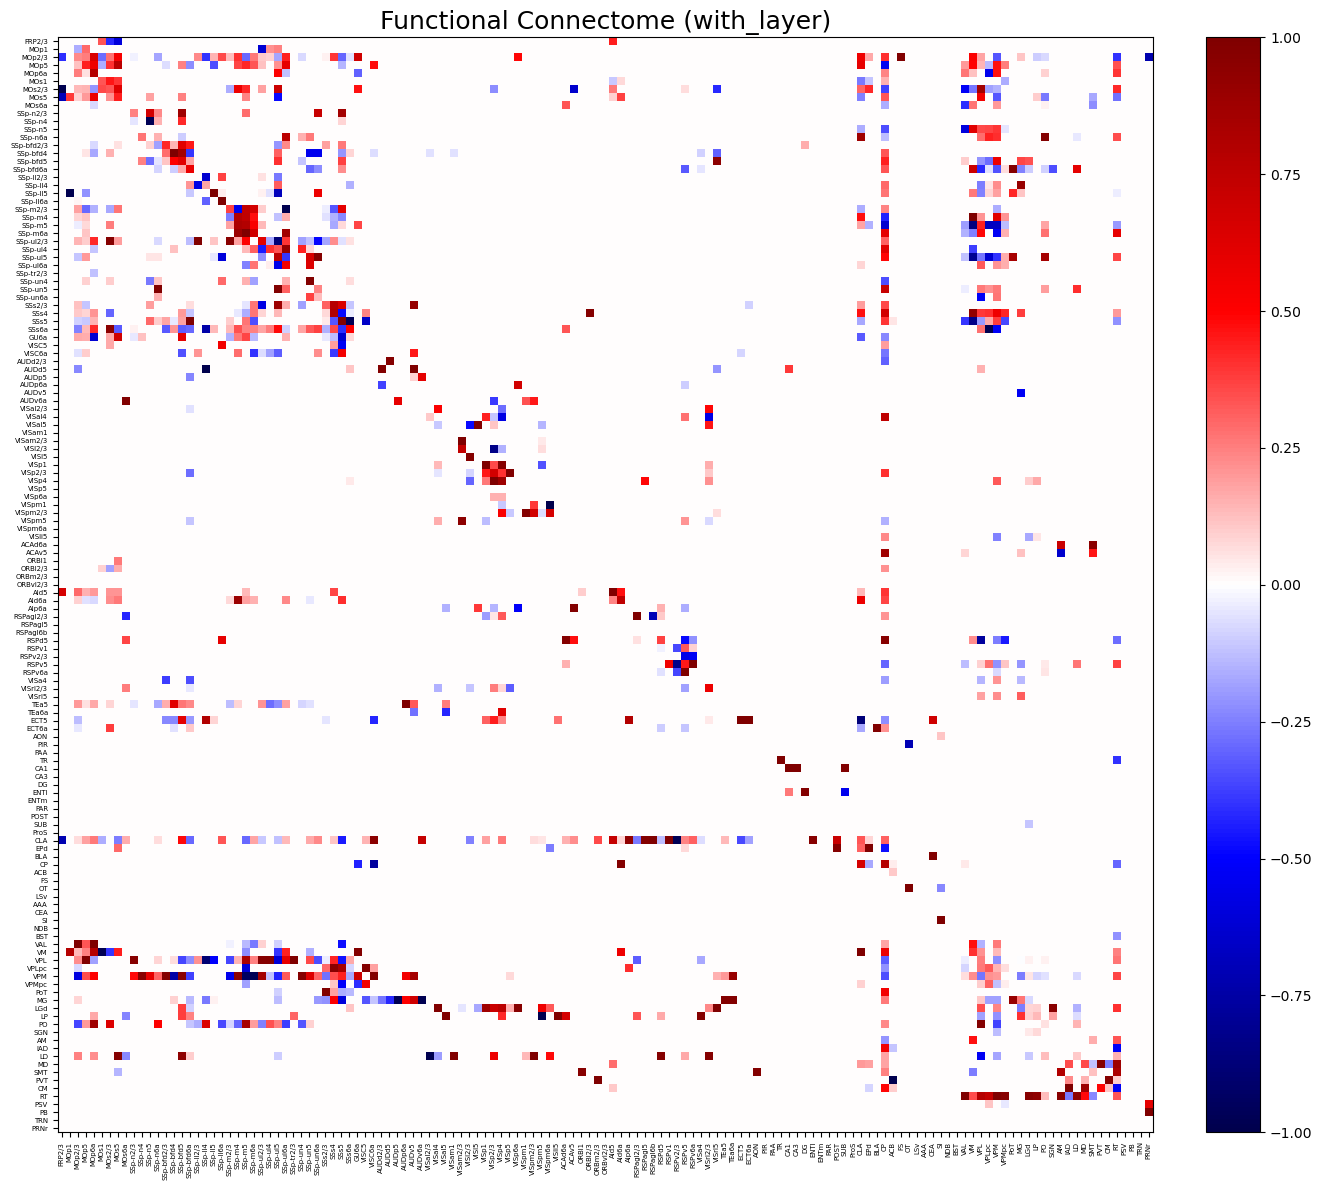

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


## stage2

In [4]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

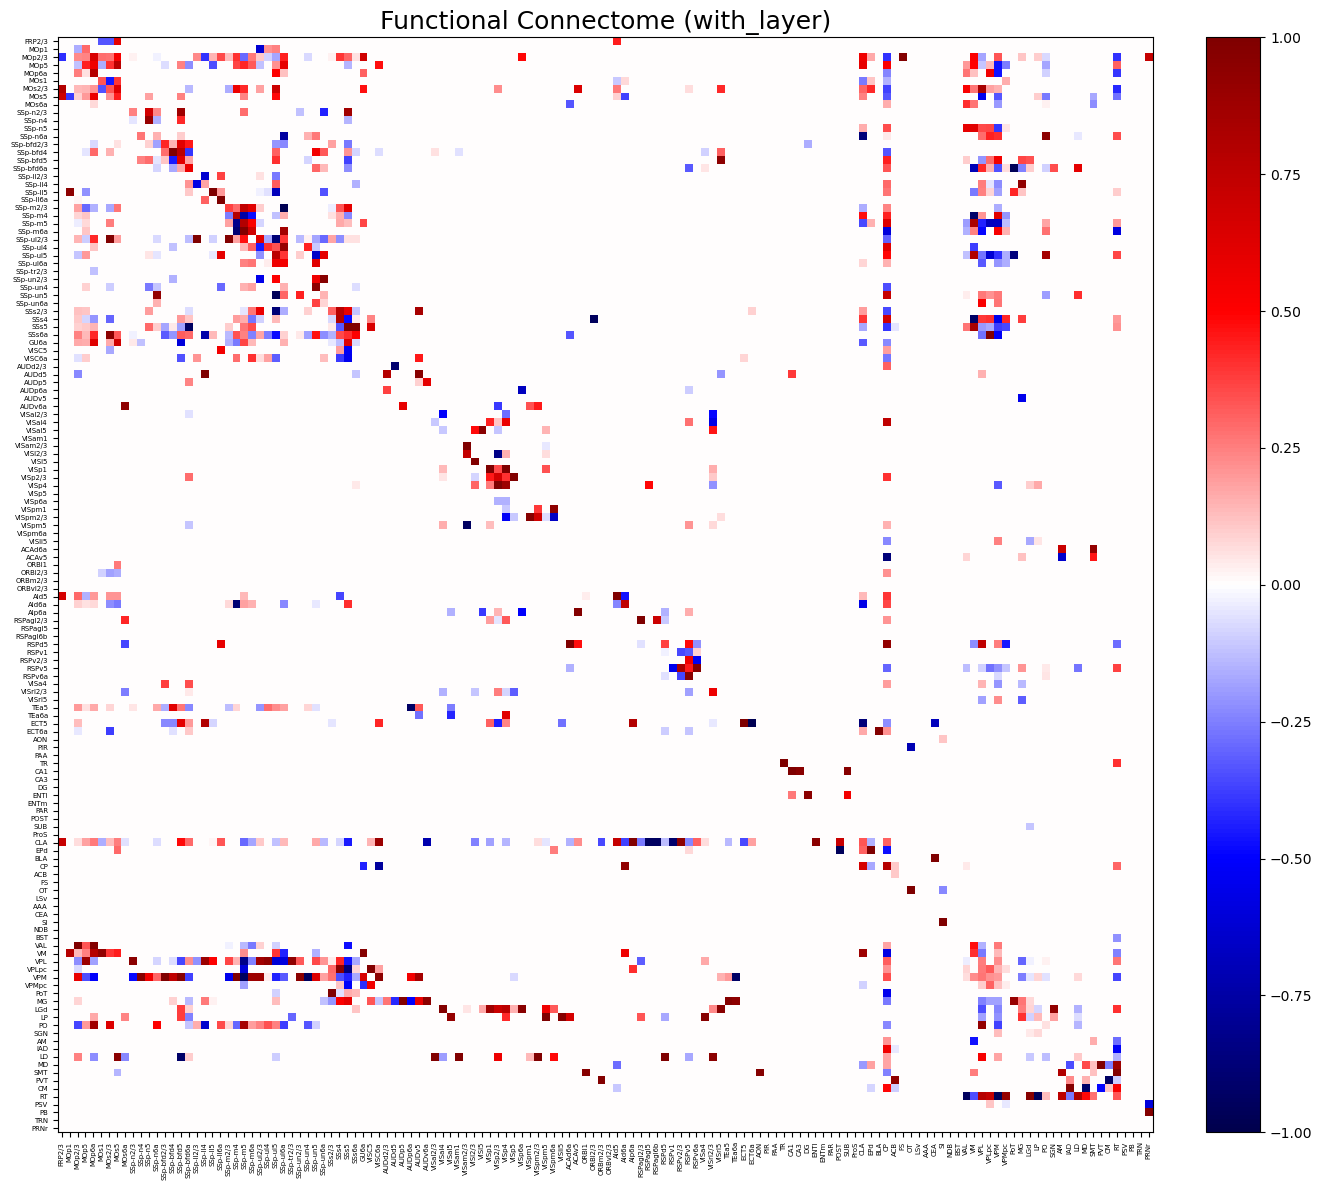

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()

## stage3

In [7]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


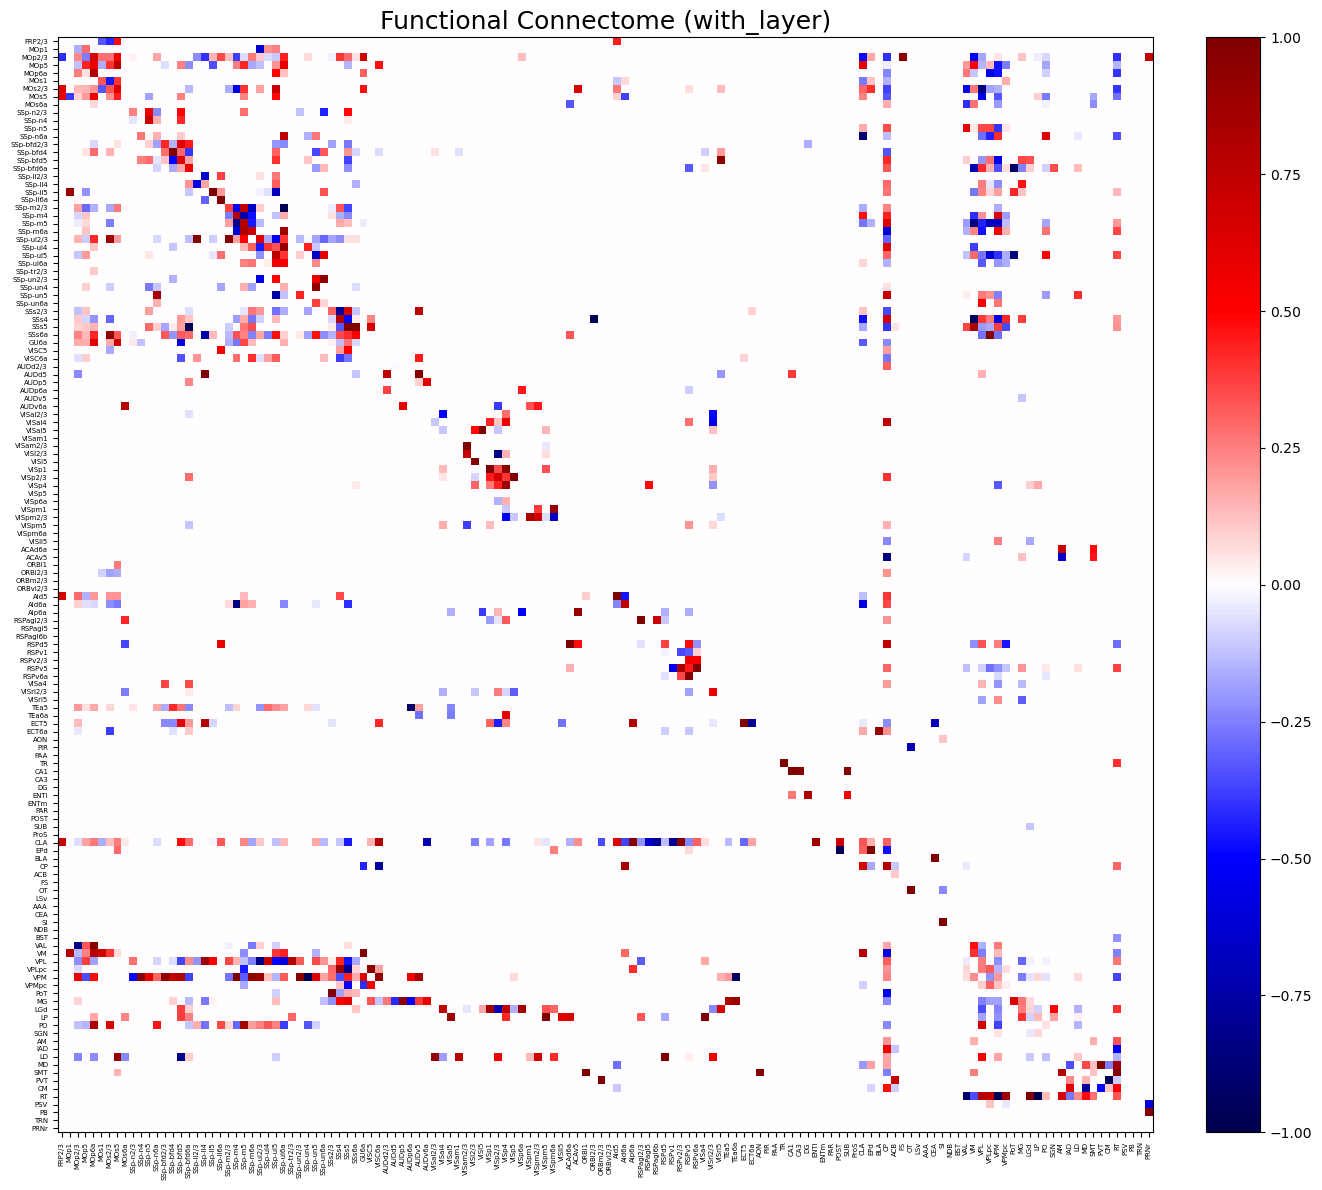

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (with_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


## Three stages similarity calculation

In [1]:
import numpy as np
import pandas as pd


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)

    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values

    return adj, labels


stage1_graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage1_label_path_1 = './result/w_layer/stage1/df_scaled.csv'

stage2_graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage2_label_path_1 = './result/w_layer/stage2/df_scaled.csv'

stage3_graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
stage3_label_path_1 = './result/w_layer/stage3/df_scaled.csv'


A1, L1 = load_mean_adj(stage1_graph_path_1, stage1_label_path_1)
A2, L2 = load_mean_adj(stage2_graph_path_1, stage2_label_path_1)
A3, L3 = load_mean_adj(stage3_graph_path_1, stage3_label_path_1)


common = sorted(set(L1) & set(L2) & set(L3))


def reorder(adj, labels, common_labels):
    label_to_idx = {
        label: idx
        for idx, label in enumerate(labels)
    }

    idx = [
        label_to_idx[label]
        for label in common_labels
    ]

    return adj[np.ix_(idx, idx)]


A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)


def calculate_mae(A, B):
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape")

    return np.mean(np.abs(A - B))


mae12 = calculate_mae(A1c, A2c)
mae13 = calculate_mae(A1c, A3c)
mae23 = calculate_mae(A2c, A3c)


print("Intersection brain regions:", len(common))
print("Number of matrix elements:", A1c.size)
print("MAE (Stage1 vs Stage2):", round(mae12, 4))
print("MAE (Stage1 vs Stage3):", round(mae13, 4))
print("MAE (Stage2 vs Stage3):", round(mae23, 4))

Intersection brain regions: 137
Number of matrix elements: 18769
MAE (Stage1 vs Stage2): 0.0175
MAE (Stage1 vs Stage3): 0.0185
MAE (Stage2 vs Stage3): 0.0055


In [14]:
import numpy as np
import pandas as pd

# ============================================================
# load learned graphs
# ============================================================
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)

    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values

    return adj, labels


# ============================================================
# learned graphs
# ============================================================
stage1_graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage1_label_path_1 = './result/w_layer/stage1/df_scaled.csv'

stage2_graph_path_1 = './result/w_layer/stage2/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage2_label_path_1 = './result/w_layer/stage2/df_scaled.csv'

stage3_graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.3_sw0.7/dynamic_full_graphs.npy'
stage3_label_path_1 = './result/w_layer/stage3/df_scaled.csv'

A1, L1 = load_mean_adj(stage1_graph_path_1, stage1_label_path_1)
A2, L2 = load_mean_adj(stage2_graph_path_1, stage2_label_path_1)
A3, L3 = load_mean_adj(stage3_graph_path_1, stage3_label_path_1)


# ============================================================
# load layer matrix
# ============================================================
df_layers = pd.read_excel('SEU_net_w_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]

layer_labels = df_layers.index.astype(str).str.strip().values
A_layer = df_layers.values.astype(float)


# ============================================================
# intersection
# ============================================================
common = sorted(list(set(L1) & set(L2) & set(L3) & set(layer_labels)))


def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)
Alc = reorder(A_layer, layer_labels, common)


# ============================================================
# compare matrices
# ============================================================
def compare_matrix(A, B):
    A = np.abs(A)
    B = np.abs(B)

    triu = np.triu_indices(A.shape[0], k=1)

    a = A[triu]
    b = B[triu]

    mae = np.mean(np.abs(a - b))
    rmse = np.sqrt(np.mean((a - b) ** 2))
    corr = np.corrcoef(a, b)[0, 1]

    return {
        "MAE": mae,
        "RMSE": rmse,
        "Pearson_r": corr
    }


# ============================================================
# results
# ============================================================
r1 = compare_matrix(A1c, Alc)
r2 = compare_matrix(A2c, Alc)
r3 = compare_matrix(A3c, Alc)

print("Intersection brain regions:", len(common))

print("\nStage1 vs Layer")
print(r1)

print("\nStage2 vs Layer")
print(r2)

print("\nStage3 vs Layer")
print(r3)

Intersection brain regions: 137

Stage1 vs Layer
{'MAE': 0.07139330349746281, 'RMSE': 0.44447257694593867, 'Pearson_r': 0.7998281172880763}

Stage2 vs Layer
{'MAE': 0.07171725596164069, 'RMSE': 0.44559174683057534, 'Pearson_r': 0.8031130035040164}

Stage3 vs Layer
{'MAE': 0.07319495685057313, 'RMSE': 0.4531115953036672, 'Pearson_r': 0.7907236210827773}
